In [4]:
# =====================================================================
#  BANK CUSTOMER CHURN PREDICTION  -  Neural Network Classifier (Keras)
#  Dataset: Churn_Modelling.csv  (Kaggle: barelydedicated/bank-customer-churn-modeling)
#  Run in Google Colab / Jupyter (each "# %%" marks one cell)
# =====================================================================
#
# ---------------------------------------------------------------------
#  PART A: HIGH-LEVEL IDEA (read this first)
# ---------------------------------------------------------------------
# PROBLEM:
#   For each bank customer, predict whether they will LEAVE the bank
#   (Exited = 1) or STAY (Exited = 0). Two possible answers = BINARY
#   CLASSIFICATION. We solve it with a NEURAL NETWORK.
#
# WHAT IS A NEURAL NETWORK? (in simple words)
#   - It is a chain of LAYERS. Each layer contains small units called NEURONS.
#   - A neuron takes numbers in, multiplies each by a WEIGHT, adds them up,
#     then passes the result through an ACTIVATION function (a small rule
#     that decides how strongly the neuron "fires").
#   - Layers:  INPUT layer (our 11 customer columns)
#              -> HIDDEN layer(s) (where the network finds patterns)
#              -> OUTPUT layer (1 neuron giving a probability of leaving, 0 to 1).
#   - TRAINING = start with random weights, make predictions, measure how wrong
#     they are (the LOSS), and nudge the weights to reduce the loss. One full
#     pass over all training customers is called an EPOCH. We repeat many epochs.
#
# ---------------------------------------------------------------------
#  PART B: THE ALGORITHM (what we will do, step by step)
# ---------------------------------------------------------------------
#  1. READ the file into a table:            df = pd.read_csv(...)
#  2. REMOVE useless columns (RowNumber, CustomerId, Surname): they are only
#     ids/names, they say nothing about whether someone leaves.
#  3. CONVERT text columns to numbers: Geography (France/Germany/Spain) and
#     Gender (Female/Male). A neural network can only do maths on numbers.
#  4. CREATE X AND y:
#        X = all the input columns (CreditScore, Age, Balance, ...) -> what the
#            network is allowed to LOOK AT;
#        y = the 'Exited' column -> the ANSWER we want it to predict.
#  5. SPLIT X and y into a TRAIN part (network learns from it) and a TEST part
#     (hidden, used only for the final exam).
#  6. NORMALIZE: put all columns on the same scale (mean 0, std 1). Without this,
#     big numbers like Salary (100000) would drown small ones like Age (40).
#  7. BUILD the baseline network, TRAIN it, and print accuracy + confusion matrix.
#  8. FIND POINTS OF IMPROVEMENT in the baseline result, IMPLEMENT them (bigger
#     network, Dropout, Early Stopping, class weights), and compare again.
#  9. COMPARE all models and write the conclusion.
# ---------------------------------------------------------------------
 
 
# %% STEP 0: IMPORT LIBRARIES
import numpy as np                        # maths on arrays
import pandas as pd                       # tables (DataFrame)
import matplotlib.pyplot as plt           # basic plots
import seaborn as sns                     # heatmap for the confusion matrix
 
from sklearn.model_selection import train_test_split        # cuts data into train and test
from sklearn.preprocessing import StandardScaler            # normalizes columns (mean 0, std 1)
from sklearn.utils.class_weight import compute_class_weight # calculates class weights (Step 8)
from sklearn.metrics import accuracy_score, confusion_matrix,classification_report 


In [5]:
import tensorflow as tf                                      # the deep-learning engine
from tensorflow.keras.models import Sequential               # a model made of layers stacked in a line
from tensorflow.keras.layers import Input, Dense, Dropout    # the building blocks (layers)
from tensorflow.keras.callbacks import EarlyStopping         # stops training at the right time (Step 8)
# Keras is the easy-to-use interface that sits on top of TensorFlow.

In [6]:
np.random.seed(42)                        # fix randomness so results repeat on every run
tf.random.set_seed(42)                    # same for the network's random starting weights
 
 
# %% STEP 1: READ THE DATASET
df = pd.read_csv('Churn_Modelling.csv')   # read the CSV file into a DataFrame called df
print(df.shape)                           # (rows, columns) -> expect (10000, 14)
print(df.head())                          # first 5 rows
print(df.isnull().sum().sum())            # total missing values (expect 0)
print(df['Exited'].value_counts())        # how many stayed (0) and left (1)
# .value_counts() counts each value. About 80% stay and 20% leave: the data is
# IMBALANCED. This matters later: a lazy model that says "everyone stays" would
# already be 80% accurate while catching zero leavers.
 

(10000, 14)
   RowNumber  CustomerId   Surname  CreditScore Geography  Gender  Age  \
0          1    15634602  Hargrave          619    France  Female   42   
1          2    15647311      Hill          608     Spain  Female   41   
2          3    15619304      Onio          502    France  Female   42   
3          4    15701354      Boni          699    France  Female   39   
4          5    15737888  Mitchell          850     Spain  Female   43   

   Tenure    Balance  NumOfProducts  HasCrCard  IsActiveMember  \
0       2       0.00              1          1               1   
1       1   83807.86              1          0               1   
2       8  159660.80              3          1               0   
3       1       0.00              2          0               0   
4       2  125510.82              1          1               1   

   EstimatedSalary  Exited  
0        101348.88       1  
1        112542.58       0  
2        113931.57       1  
3         93826.63       0  
4

In [7]:
# %% STEP 2: REMOVE USELESS COLUMNS
df = df.drop(columns=['RowNumber', 'CustomerId', 'Surname'])
# .drop(columns=[...]) removes those columns. They are row numbers, customer ids and
# surnames: unique labels with no pattern the network could learn from.

In [8]:
 
# %% STEP 3: CONVERT TEXT COLUMNS TO NUMBERS
df = pd.get_dummies(df, columns=['Geography', 'Gender'], drop_first=True, dtype=int)
# pd.get_dummies = "one-hot encoding": replaces a text column by 0/1 columns,
# one per category.
#   Geography (France/Germany/Spain) -> Geography_Germany, Geography_Spain
#   Gender (Female/Male)             -> Gender_Male
# drop_first=True drops the first category of each column (France, Female): it is
# implied when all the others are 0, so keeping it would only repeat information.
# dtype=int makes the new columns 0/1 numbers (not True/False).
print(df.head())                          # check: no text columns are left
 

   CreditScore  Age  Tenure    Balance  NumOfProducts  HasCrCard  \
0          619   42       2       0.00              1          1   
1          608   41       1   83807.86              1          0   
2          502   42       8  159660.80              3          1   
3          699   39       1       0.00              2          0   
4          850   43       2  125510.82              1          1   

   IsActiveMember  EstimatedSalary  Exited  Geography_Germany  \
0               1        101348.88       1                  0   
1               1        112542.58       0                  0   
2               0        113931.57       1                  0   
3               0         93826.63       0                  0   
4               1         79084.10       0                  0   

   Geography_Spain  Gender_Male  
0                0            0  
1                1            0  
2                0            0  
3                0            0  
4                1            

In [9]:
# %% STEP 4: CREATE X (INPUTS) AND y (ANSWER)
# We want one table X holding everything the network may look at, and one column y
# holding the correct answer for each customer.
X = df.drop(columns=['Exited'])
# X = every column EXCEPT 'Exited'. So X now contains: CreditScore, Age, Tenure,
# Balance, NumOfProducts, HasCrCard, IsActiveMember, EstimatedSalary,
# Geography_Germany, Geography_Spain, Gender_Male  -> exactly 11 input columns.
# (We must remove 'Exited' from X, otherwise the network would simply read the answer.)
y = df['Exited']
# y = only the 'Exited' column: 1 = customer left, 0 = customer stayed.
print("X shape:", X.shape, "| y shape:", y.shape)    # (10000, 11) and (10000,)

X shape: (10000, 11) | y shape: (10000,)


In [10]:
# %% STEP 5: SPLIT INTO TRAIN AND TEST
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y)
# test_size=0.3  -> 30% of customers are hidden for testing, 70% used for training.
# random_state=42 -> same shuffle every run (repeatable results).
# stratify=y      -> keep the same stay/leave ratio (80/20) in both parts, so the
#                    test set is a fair copy of the real situation.
# Returns 4 parts: train inputs, test inputs, train answers, test answers.

In [11]:
# %% STEP 6: NORMALIZE THE DATA (mean 0, standard deviation 1)
# Formula for every column:   z = (value - column_mean) / column_std
scaler = StandardScaler()                       # create the scaler object
X_train = scaler.fit_transform(X_train)
# fit_transform = fit() learns each column's mean and std FROM THE TRAIN DATA,
# then transform() applies the formula. Both in one call.
X_test = scaler.transform(X_test)
# transform() only: apply the SAME mean/std learned from train. We never fit on
# test data, otherwise test information would leak into training ("data leakage").
# (Both outputs are now plain NumPy arrays, which Keras accepts directly.)
print("Mean of first train column ~", X_train[:, 0].mean().round(3))   # should be about 0

Mean of first train column ~ 0.0


In [12]:
# %% STEP 7: HELPER FUNCTIONS (so we don't repeat code for each model)
def build_model(hidden_units=(6, 6), dropout=0.0):
    """Creates a NEW network. hidden_units = neurons in each hidden layer."""
    model = Sequential()                                    # empty network: layers will be added in order
    model.add(Input(shape=(X_train.shape[1],)))             # input layer: tells the network it gets 11 numbers per customer
    for units in hidden_units:                              # one pass of the loop = one hidden layer
        model.add(Dense(units, activation='relu'))
        # Dense = a fully connected layer: every neuron receives ALL outputs of the previous layer.
        # units = how many neurons in this layer.
        # activation='relu' = ReLU: output = max(0, input). Cheap, fast, and the standard
        # choice for hidden layers; it lets the network learn non-straight-line patterns.
        if dropout > 0:
            model.add(Dropout(dropout))
            # Dropout(0.2): during training, randomly switch off 20% of this layer's neurons
            # each step. This stops the network from memorising the training customers
            # (OVERFITTING) and forces it to learn more general patterns.
    model.add(Dense(1, activation='sigmoid'))
    # Output layer: 1 neuron. activation='sigmoid' squeezes any number into 0..1, so the
    # result reads as "probability that the customer leaves".
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    # compile = choose HOW the network will learn:
    #   optimizer='adam'          : the algorithm that updates the weights (a smart,
    #                               self-adjusting version of gradient descent).
    #   loss='binary_crossentropy': the error measure for 2-class problems; it is large
    #                               when the network is confidently wrong.
    #   metrics=['accuracy']      : also report accuracy while training.
    return model
 
 
def evaluate(name, model):
    """Predicts on the test set and prints accuracy, confusion matrix and report."""
    prob = model.predict(X_test, verbose=0)
    # predict() gives, for each test customer, a probability between 0 and 1.
    # verbose=0 hides the progress bar.
    pred = (prob > 0.5).astype(int).ravel()
    # Threshold rule: probability above 0.5 -> predict 1 (leaves), else 0 (stays).
    # .astype(int) turns True/False into 1/0; .ravel() flattens the shape (3000,1) to (3000,).
    acc = accuracy_score(y_test, pred)
    cm = confusion_matrix(y_test, pred)
    print(f"\n========== {name} ==========")
    print("Accuracy:", round(acc, 4))
    print("Confusion matrix [[TN, FP], [FN, TP]]:\n", cm)
    print(classification_report(y_test, pred, target_names=['Stays', 'Leaves']))
    return pred, acc, cm
# How to read the confusion matrix (1 = Leaves is the "positive" class):
#   TN = stayed, predicted stay (correct)     FP = stayed, predicted leave (false alarm)
#   FN = LEFT, predicted stay (missed churner) TP = left, predicted leave (caught)
# Recall of 'Leaves' = TP / (TP + FN) = how many of the real leavers we caught.

In [13]:
# %% STEP 8: MODEL 1 - BASELINE NETWORK (like the reference code)
model_1 = build_model(hidden_units=(6, 6), dropout=0.0)
model_1.summary()
# summary() prints the layers. Parameters (weights+biases) per layer:
#   Layer 1: 11 inputs x 6 neurons + 6 biases = 72
#   Layer 2: 6 x 6 + 6 = 42
#   Output : 6 x 1 + 1 = 7        -> total 121 parameters to learn.
 
model_1.fit(X_train, y_train, batch_size=32, epochs=50, verbose=0)
# fit() = TRAINING.
#   epochs=50     : 50 full passes over the training customers.
#   batch_size=32 : weights are updated after every 32 customers (not after each one),
#                   which is faster and steadier. (The reference used 10: slower.)
#   verbose=0     : do not print every epoch.
pred_1, acc_1, cm_1 = evaluate("Model 1: Baseline (6-6)", model_1)
 

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 6)              │            72 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │            42 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             7 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 121 (484.00 B)

 Trainable params: 121 (484.00 B)

 Non-trainable params: 0 (0.00 B)


========== Model 1: Baseline (6-6) ==========
Accuracy: 0.863
Confusion matrix [[TN, FP], [FN, TP]]:
 [[2297   92]
 [ 319  292]]
              precision    recall  f1-score   support

       Stays       0.88      0.96      0.92      2389
      Leaves       0.76      0.48      0.59       611

    accuracy                           0.86      3000
   macro avg       0.82      0.72      0.75      3000
weighted avg       0.85      0.86      0.85      3000



In [14]:
# %% STEP 9: POINTS OF IMPROVEMENT (what the baseline result tells us)
# Typical baseline result: accuracy ~83-84%, but recall for 'Leaves' only ~0.3.
# PROBLEMS and FIXES:
#  1. Network too small (only 6 neurons per layer)    -> use more neurons: (16, 8).
#  2. Risk of overfitting / training for a fixed 50 epochs
#                                                      -> Dropout + Early Stopping.
#  3. Imbalanced data (80% stay): the network learns to favour "stays", so it misses
#     most leavers (the customers the bank cares about)
#                                                      -> class weights (Model 3).
 
 

Training stopped after 71 epochs

========== Model 2: Improved (16-8, Dropout, EarlyStopping) ==========
Accuracy: 0.8647
Confusion matrix [[TN, FP], [FN, TP]]:
 [[2323   66]
 [ 340  271]]
              precision    recall  f1-score   support

       Stays       0.87      0.97      0.92      2389
      Leaves       0.80      0.44      0.57       611

    accuracy                           0.86      3000
   macro avg       0.84      0.71      0.75      3000
weighted avg       0.86      0.86      0.85      3000



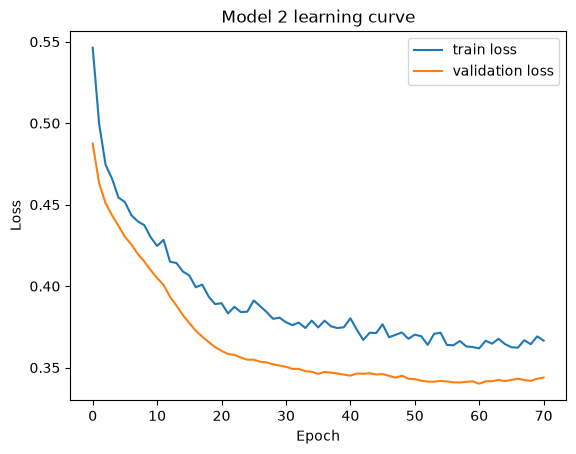

In [15]:
# %% STEP 10: MODEL 2 - IMPROVED NETWORK (bigger + Dropout + Early Stopping)
model_2 = build_model(hidden_units=(16, 8), dropout=0.2)
early_stop = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
# EarlyStopping: after every epoch, check the loss on VALIDATION data (data the network is
# not trained on).
#   monitor='val_loss'         : watch the validation loss.
#   patience=10                : stop if it has not improved for 10 epochs in a row.
#   restore_best_weights=True  : go back to the best weights seen (not the last ones).
history_2 = model_2.fit(X_train, y_train, batch_size=32, epochs=100,
                        validation_split=0.2, callbacks=[early_stop], verbose=0)
# validation_split=0.2 : Keras holds back 20% of the TRAIN data to check progress each
#                        epoch (the test set stays untouched).
# epochs=100           : just an upper limit; Early Stopping usually ends sooner.
# fit() returns a History object: history.history['loss'] and ['val_loss'] hold the
# error per epoch, which we plot below.
print("Training stopped after", len(history_2.history['loss']), "epochs")
pred_2, acc_2, cm_2 = evaluate("Model 2: Improved (16-8, Dropout, EarlyStopping)", model_2)
 
plt.plot(history_2.history['loss'], label='train loss')
plt.plot(history_2.history['val_loss'], label='validation loss')
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.title('Model 2 learning curve'); plt.legend()
plt.show()
# Both curves falling = learning. Validation curve flattening or rising = overfitting
# starts; Early Stopping stops us there.

In [16]:
# %% STEP 11: MODEL 3 - IMPROVED NETWORK + CLASS WEIGHTS
weights = compute_class_weight(class_weight='balanced', classes=np.array([0, 1]), y=y_train)
# 'balanced' gives the rare class a bigger weight: weight = n_samples / (2 x class_count).
# Leavers (20%) get about 2.5, stayers (80%) about 0.6.
class_weight = {0: float(weights[0]), 1: float(weights[1])}
# Keras wants a dictionary {class: weight}.
print("Class weights:", class_weight)
 
model_3 = build_model(hidden_units=(16, 8), dropout=0.2)
model_3.fit(X_train, y_train, batch_size=32, epochs=100, validation_split=0.2,
            callbacks=[EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)],
            class_weight=class_weight, verbose=0)
# class_weight=...: a mistake on a leaver now costs about 4x more than a mistake on a stayer,
# so the network pays more attention to leavers.
pred_3, acc_3, cm_3 = evaluate("Model 3: Improved + class weights", model_3)

Class weights: {0: 0.6279153211338356, 1: 2.4544179523141656}

========== Model 3: Improved + class weights ==========
Accuracy: 0.758
Confusion matrix [[TN, FP], [FN, TP]]:
 [[1774  615]
 [ 111  500]]
              precision    recall  f1-score   support

       Stays       0.94      0.74      0.83      2389
      Leaves       0.45      0.82      0.58       611

    accuracy                           0.76      3000
   macro avg       0.69      0.78      0.70      3000
weighted avg       0.84      0.76      0.78      3000



                     Model  Accuracy  Recall (Leaves)  F1 (Leaves)
                1 Baseline     0.863            0.478        0.587
                2 Improved     0.865            0.444        0.572
3 Improved + class weights     0.758            0.818        0.579


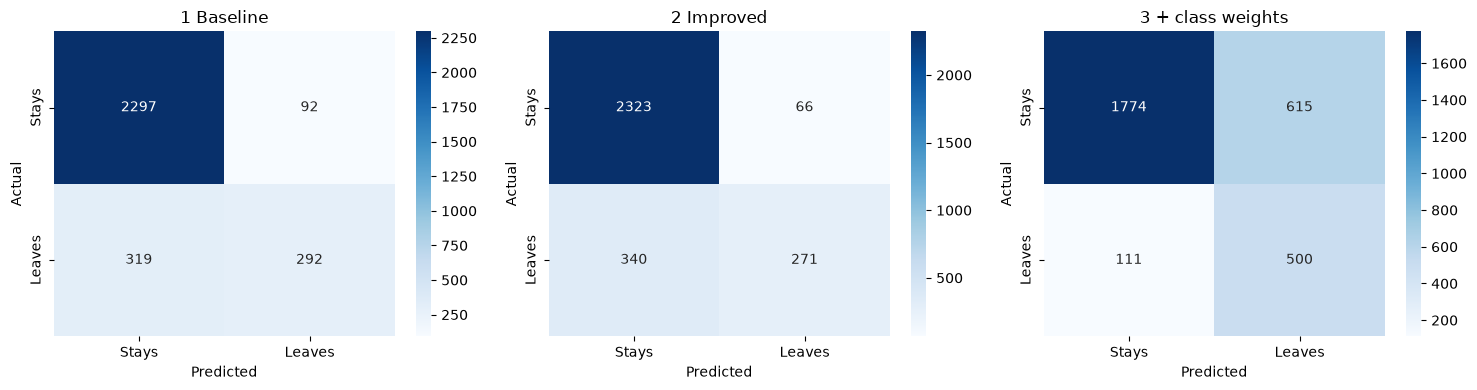

In [17]:
# %% STEP 12: COMPARE ALL MODELS
from sklearn.metrics import recall_score, f1_score
rows = []
for name, pred, acc in [('1 Baseline', pred_1, acc_1),
                        ('2 Improved', pred_2, acc_2),
                        ('3 Improved + class weights', pred_3, acc_3)]:
    rows.append({'Model': name, 'Accuracy': acc,
                 'Recall (Leaves)': recall_score(y_test, pred),   # share of real leavers caught
                 'F1 (Leaves)': f1_score(y_test, pred)})          # balance of precision and recall
print(pd.DataFrame(rows).round(3).to_string(index=False))
 
# Confusion matrices side by side
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, cm, title in zip(axes, [cm_1, cm_2, cm_3], ['1 Baseline', '2 Improved', '3 + class weights']):
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['Stays', 'Leaves'], yticklabels=['Stays', 'Leaves'])
    # annot=True writes the counts in the cells; fmt='d' = whole numbers
    ax.set_xlabel('Predicted'); ax.set_ylabel('Actual'); ax.set_title(title)
plt.tight_layout(); plt.show()

In [18]:
# %% STEP 13: CONCLUSION (write in your journal, with YOUR numbers)
# - Baseline: decent accuracy but it misses most customers who leave (low recall).
# - Model 2 (bigger network, Dropout, Early Stopping): usually a small gain in accuracy
#   and a more stable result.
# - Model 3 (class weights): accuracy may drop a little, but recall for 'Leaves' rises
#   a lot, so far more churners are caught. For a bank, missing a customer who leaves is
#   costlier than a false alarm, so Model 3 is often the more useful model even though
#   its accuracy is lower. Accuracy alone is misleading on imbalanced data.